# Features: machine M01
Window features for the 13 M01 operations that have both good and bad recordings. All numbers below come from the code cells.

## Day 3 – windows, features and the anomaly over time
Notebook 01 compared whole recordings. The board only ever sees one window at a time, so today I cut the recordings into windows, compute the features per window, and check whether the extra spindle energy shows up in every window of a bad run or only in parts of it.

### Setup
Same facts and file index as notebook 01: 2000 Hz (README line 15), columns X, Y, Z (README line 37), and the spindle speed per operation from the paper's Table 1. Window length 1024 samples and step 256 are fixed project decisions: 512 ms per window, one new result every 128 ms.

In [1]:
from pathlib import Path
import h5py, numpy as np, pandas as pd
import matplotlib.pyplot as plt

FS = 2000                 # Hz, README line 15
AXES = 'XYZ'              # README line 37
WIN, STEP = 1024, 256     # 512 ms window, new result every 128 ms
SPEED = dict(OP01=250, OP02=200, OP03=250, OP04=250, OP05=200, OP06=250, OP07=200,
             OP08=250, OP09=250, OP10=250, OP11=250, OP12=250, OP14=250)  # Hz, paper Table 1
DIR = Path('../data/CNC_Machining/data/M01')
GOOD, BAD = '#2a78d6', '#eb6834'

def load(path):
    """(n, 3) array in counts, columns X, Y, Z."""
    with h5py.File(path) as f:
        return f['vibration_data'][()].astype(float)

rows = []
for p in sorted(DIR.glob('OP*/*/*.h5')):
    _, month, year, op, num = p.stem.split('_')
    if op in SPEED:  # OP00 and OP13 have no bad recordings
        rows.append(dict(op=op, period=pd.to_datetime(month + year, format='%b%Y').strftime('%Y-%m'),
                         label=p.parent.name, num=num, path=p))
idx = pd.DataFrame(rows)
print(idx.groupby('label').size().to_dict(), 'recordings in', idx['op'].nunique(), 'operations')

{'bad': 34, 'good': 413} recordings in 13 operations


### Windows
`sliding_window_view` gives every 1024-sample stretch without copying data, and `[::STEP]` keeps one every 256 samples. I subtract each window's own mean, because a constant offset is not vibration (Z sits near -1000 counts).

In [2]:
def windows(x):
    """(n, 3) signal -> (n_windows, 3, WIN), mean removed per window and axis."""
    w = np.lib.stride_tricks.sliding_window_view(x, WIN, axis=0)[::STEP]
    return w - w.mean(axis=2, keepdims=True)

x = load(idx['path'][0])
print(len(x), 'samples ->', len(windows(x)), 'windows of shape', windows(x).shape[1:])

38983 samples -> 149 windows of shape (3, 1024)


### Features per window
Four values per axis, 12 in total:
- **RMS:** the average vibration strength.
- **Peak-to-peak:** the distance between the highest and lowest sample.
- **Crest factor:** peak divided by RMS, which is high for short knocks and low for steady vibration.
- **Spindle band energy:** the FFT energy within ±10% of the operation's spindle speed, the feature notebook 01 found. Before the FFT each window is multiplied by a Hann window (a smooth bump that goes to zero at both ends), so the cut edges don't smear energy across frequencies. I store it in dB, 10 · log10(energy), so +10 means ten times the energy.

EPS keeps the log and the division finite on a perfectly flat window.

In [3]:
EPS = 1e-6
HANN = np.hanning(WIN)
FREQ = np.fft.rfftfreq(WIN, 1 / FS)  # 1.95 Hz per FFT bin
NAMES = [f'{k} {ax}' for k in ['rms', 'p2p', 'crest', 'spindle_db'] for ax in AXES]

def features(x, op):
    """(n, 3) signal -> (n_windows, 12), ordered as NAMES."""
    w = windows(x)
    rms = np.sqrt((w ** 2).mean(axis=2))
    p2p = w.max(axis=2) - w.min(axis=2)
    crest = np.abs(w).max(axis=2) / (rms + EPS)
    power = np.abs(np.fft.rfft(w * HANN, axis=2)) ** 2
    near = np.abs(FREQ - SPEED[op]) <= .1 * SPEED[op]
    spindle = 10 * np.log10(power[:, :, near].sum(axis=2) + EPS)
    return np.hstack([rms, p2p, crest, spindle])

### Check with test signals
A sine with amplitude 1 must give RMS 0.7071 (1/√2), peak-to-peak 2 and crest factor 1.414 (√2). A 250 Hz sine should have far more spindle energy for OP01 than a 100 Hz sine, which lies outside the band.

In [4]:
t = np.arange(4 * WIN) / FS
for hz in [250, 100]:
    s = np.sin(2 * np.pi * hz * t)
    F = features(np.column_stack([s, s, s]), 'OP01')
    print(f'{hz} Hz sine:', dict(zip(['rms', 'p2p', 'crest', 'spindle_db'], F[0, ::3].round(4))))

250 Hz sine: {'rms': np.float64(0.7071), 'p2p': np.float64(2.0), 'crest': np.float64(1.4142), 'spindle_db': np.float64(49.9215)}
100 Hz sine: {'rms': np.float64(0.7065), 'p2p': np.float64(2.0), 'crest': np.float64(1.4178), 'spindle_db': np.float64(-58.0715)}


### All recordings
Features for every window of all 447 recordings. This reads every file once.

In [5]:
F = {i: features(load(p), op) for i, (p, op) in enumerate(zip(idx['path'], idx['op']))}
idx['windows'] = [len(F[i]) for i in idx.index]
print(idx.groupby('label')['windows'].sum().to_dict(), 'windows')
print('all finite:', all(np.isfinite(v).all() for v in F.values()))

{'bad': 11179, 'good': 164801} windows
all finite: True


### Idle windows
When the machine stands still there is almost no vibration, and such windows say nothing about the process. The histogram shows the largest axis RMS of every good window, with both axes on a log scale so small groups stay visible. There is a small separate group at about 10 to 25 counts (the machine standing still), a dip near 30 counts, and then the running machine. I call a window idle when its largest axis RMS is below 30 counts, at the dip.

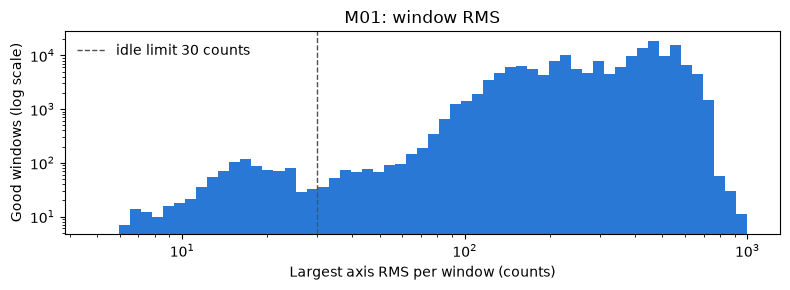

good: 0.52% of windows idle
bad: 0.00% of windows idle


In [6]:
IDLE = 30  # counts, largest axis RMS: the dip between the idle group and the running machine
level = lambda v: v[:, :3].max(axis=1)  # the first 3 columns are RMS X, Y, Z
good_level = np.concatenate([level(F[i]) for i in idx.index[idx['label'] == 'good']])
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(good_level, np.geomspace(5, 1000, 60), color=GOOD)
ax.axvline(IDLE, color='#52514e', ls='--', lw=1, label=f'idle limit {IDLE} counts')
ax.set(xscale='log', yscale='log', xlabel='Largest axis RMS per window (counts)', ylabel='Good windows (log scale)', title='M01: window RMS')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
for lab in ['good', 'bad']:
    v = np.concatenate([level(F[i]) for i in idx.index[idx['label'] == lab]])
    print(f'{lab}: {(v < IDLE).mean():.2%} of windows idle')

### Is the anomaly in every window?
For each operation and period I take the good windows (idle ones left out) and find the 99th percentile of the spindle energy per axis. That is the level only 1% of normal windows reach. Then I count, for each bad recording, the share of its windows that go above that level on at least one axis. For comparison, the same share for the good windows themselves is printed. It isn't 1%, because three axes get three chances. These limits are fitted on the same good windows they are checked on, so this describes the data. It is not a test of a model.

In [7]:
SPIN = [NAMES.index(f'spindle_db {ax}') for ax in AXES]
rows, good_share = [], []
for (op, period), g in idx.groupby(['op', 'period']):
    good = [F[i][level(F[i]) >= IDLE][:, SPIN] for i in g.index[g['label'] == 'good']]
    if not good or not (g['label'] == 'bad').any():
        continue
    limit = np.percentile(np.vstack(good), 99, axis=0)
    good_share.append((np.vstack(good) > limit).any(axis=1))
    for i in g.index[g['label'] == 'bad']:
        v = F[i][level(F[i]) >= IDLE][:, SPIN]
        rows.append(dict(op=op, period=period, num=g.loc[i, 'num'], windows=len(v), above=(v > limit).any(axis=1).mean()))
share = pd.DataFrame(rows)
print(share.assign(above=share['above'].map('{:.0%}'.format)).to_string(index=False))
print(f"\ngood windows above the limit: {np.concatenate(good_share).mean():.1%}")
for t in [.9, .5, .1]:
    print(f"bad recordings with more than {t:.0%} of windows above: {(share['above'] > t).sum()} of {len(share)}")

  op  period num  windows above
OP01 2019-02 000      180   98%
OP01 2019-08 000      149  100%
OP02 2019-02 000      277  100%
OP03 2019-08 000      542  100%
OP04 2019-02 000      484  100%
OP04 2019-08 000      261  100%
OP05 2019-02 000      113   95%
OP05 2019-02 001      112   82%
OP05 2019-08 000      101  100%
OP05 2021-02 000      114  100%
OP06 2019-08 000      661  100%
OP06 2021-08 000      684  100%
OP06 2021-08 001      622   99%
OP06 2021-08 002      700   99%
OP07 2019-02 000      143  100%
OP07 2019-08 000      122  100%
OP07 2021-08 000      161   93%
OP07 2021-08 001      176   85%
OP08 2019-02 000      247   98%
OP08 2019-02 001      247   98%
OP08 2019-02 002      249   98%
OP09 2019-08 000      754    5%
OP10 2019-02 000      322   99%
OP10 2019-02 001      332   99%
OP10 2019-02 002      333   99%
OP11 2019-02 000      415  100%
OP11 2019-02 001      417  100%
OP11 2019-02 002      415  100%
OP11 2021-02 000      348  100%
OP12 2019-02 000      330   99%
OP12 201

### The spindle energy over time
Three bad recordings: a strong case, a weak one, and OP09, which looked normal in notebook 01. For each window the plot shows how far the spindle energy lies above the 99% normal level of its group, on the axis where it's highest. Above 0 dB the window is louder at the spindle speed than 99% of normal windows. One good run from the same group is drawn for comparison.

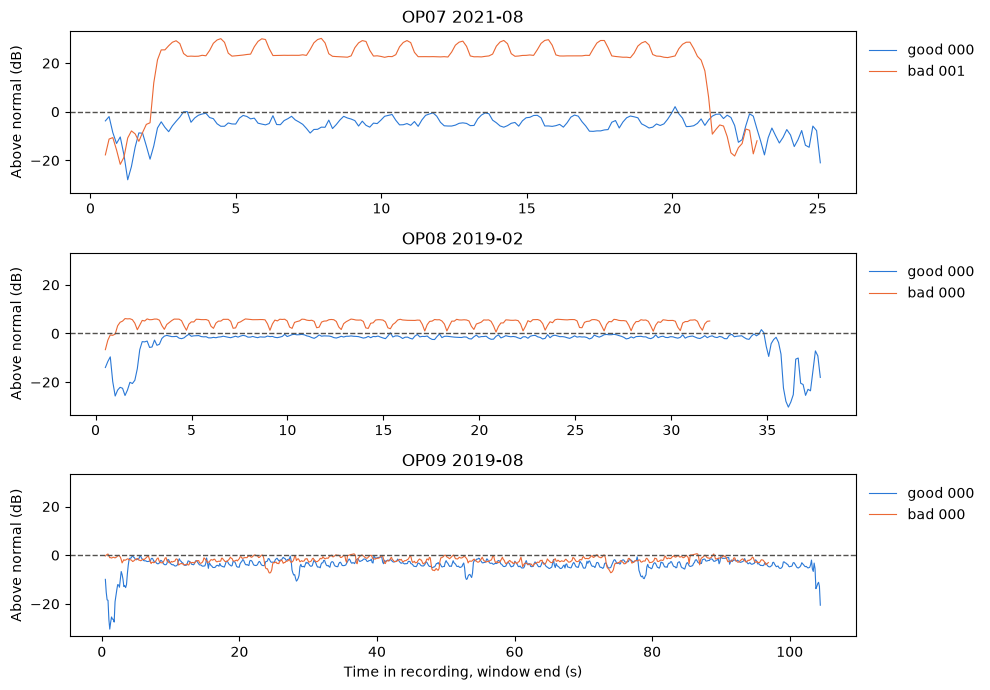

In [8]:
def margin(i, limit):
    """dB above the group's 99% normal level, highest axis, per window."""
    return (F[i][:, SPIN] - limit).max(axis=1)

cases = [('OP07', '2021-08', '001'), ('OP08', '2019-02', '000'), ('OP09', '2019-08', '000')]
fig, axs = plt.subplots(len(cases), 1, figsize=(10, 7), sharey=True)
for ax, (op, period, num) in zip(axs, cases):
    g = idx[(idx['op'] == op) & (idx['period'] == period)]
    good_i = g.index[g['label'] == 'good']
    bad_i = g.index[(g['label'] == 'bad') & (g['num'] == num)][0]
    limit = np.percentile(np.vstack([F[i][level(F[i]) >= IDLE][:, SPIN] for i in good_i]), 99, axis=0)
    for i, color, name in [(good_i[0], GOOD, 'good ' + g.loc[good_i[0], 'num']), (bad_i, BAD, 'bad ' + num)]:
        ax.plot((np.arange(len(F[i])) * STEP + WIN) / FS, margin(i, limit), color=color, lw=.8, label=name)
    ax.axhline(0, color='#52514e', ls='--', lw=1)
    ax.set(title=f'{op} {period}', ylabel='Above normal (dB)')
    ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
axs[-1].set_xlabel('Time in recording, window end (s)')
fig.tight_layout()
fig.savefig('../results/figures/m01_spindle_over_time.png', dpi=150)
plt.show()

### What Day 3 shows
- **The features work.** The 250 Hz sine gives exactly RMS 0.7071, peak-to-peak 2 and crest factor 1.4142, and about 108 dB more spindle energy than the 100 Hz sine. The 100 Hz RMS is 0.7065, not 0.7071, because 1024 samples hold 51.2 periods of a 100 Hz sine and the leftover part period shifts the average a little. All 175,980 windows give finite values.
- **The anomaly lasts the whole run.** In 30 of 33 bad recordings, more than 90% of the windows are above the 99% normal spindle level of their group, against 2.5% of good windows. So it isn't a short burst. Any window of a bad run is enough to see it, which means the board can react within a few windows, and alarm smoothing (k of the last n windows) won't cost detections.
- **Where it starts.** In OP07 2021-08 bad 001 the first 2 s and the last 1.5 s are normal, and the excess appears when the cutting starts. Most bad files start right in the anomaly because the authors cut their start.
- **OP09 2019-08 stays undetectable** with this feature: 5% of its windows are above the level, about the same as good windows (2.5%).
- **Idle windows exist only in good files** (0.52% of good windows, none in bad ones), another effect of the cut files. Dropping idle windows before training and scoring removes that unfair difference.

These limits were fitted on the same good windows they are compared with, so this is a description of the data, not a model result. A fair test needs the split by recording (next step).